# 🧬 MotifBench: full analysis

**Classic vs modern motif discovery under varying motif strength, background models and pseudocounts.**
CS4054 Bioinformatics · Aaleen Fatima · Laiba Amjad · Mariyam Pasha

This notebook reproduces every figure, table and statistical test in the report from one file, `results/results.csv` (26,550 runs). Run it top to bottom with **Run All**; it takes about a minute.

**Research questions (from the proposal)**
1. When is each classic algorithm (Greedy, Randomized, Gibbs) reliable?
2. How far behind STREME are they?
3. How much of that gap comes down to **pseudocounts** and the **background model**?

In [1]:
import os, sys, json
# run from the repo root whether the notebook is opened from notebooks/ or the root
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
from IPython.display import Image, display, Markdown

from evaluation.plots import load_results, make_all, mean_ci
from evaluation.stats import standard_claims, streme_gap, reliability

pd.set_option("display.width", 160, "display.max_columns", 30)
df = load_results("results/results.csv")
syn = df[df.data_type == "synthetic"]
real = df[df.data_type == "real_sites"]
print(f"{len(df):,} runs  ·  {syn.dataset.nunique():,} synthetic + {real.dataset.nunique()} real-site datasets")

26,550 runs  ·  1,680 synthetic + 90 real-site datasets


## 1 · The experiment grid

Every synthetic dataset is 50 sequences × 500 bp with one planted site per sequence. Each of Greedy / Randomized / Gibbs runs in **4 configurations** (pseudocounts on/off × scoring background uniform/shuffled). STREME (MEME Suite, default settings) and two reference baselines run once per dataset:

* **oracle_scan**: scan each sequence with the *true* matrix; no method can locate the sites better (the **ceiling**)
* **random**: random sites (the **chance** floor)

In [2]:
grid = (df.assign(config=df.pseudocount.fillna("-") + " / " + df.bg_model)
          .groupby(["data_type", "algorithm"]).agg(runs=("dataset", "size"),
                                                   datasets=("dataset", "nunique"))
          .unstack(0))
display(grid)
cfg = json.load(open("results/run_config.json"))
print("search budget:", cfg["budget"])
print("algorithms told the true width:", cfg["algorithms_know_true_width"])

runs             datasets          
data_type   real_sites synthetic real_sites synthetic
algorithm                                            
gibbs              360      6720         90      1680
greedy             360      6720         90      1680
oracle_scan         90      1680         90      1680
random              90      1680         90      1680
randomized         360      6720         90      1680
streme              90      1680         90      1680

search budget: {'greedy': {}, 'randomized': {'n_restarts': 200}, 'gibbs': {'n_restarts': 40, 'n_iterations': 2000}}
algorithms told the true width: True


### Motif strength, reported as real information content

Strength is set by blending each JASPAR matrix with the uniform distribution, `P' = (1-α)·P + α·0.25`, with α chosen by bisection so the blended matrix keeps a given **fraction of the original information content**. The actual IC values (bits, whole motif) are:

In [3]:
ic = syn.groupby(["motif_id", "strength"]).true_ic.first().unstack().round(2)
ic.insert(0, "width", syn.groupby("motif_id").true_width.first())
ic

strength,width,0.2,0.4,0.6,0.7,0.8,0.9,1.0
motif_id,,,,,,,,
MA0001.3,10,2.28,4.56,6.84,7.98,9.13,10.27,11.41
MA0002.2,11,2.08,4.16,6.24,7.28,8.32,9.36,10.40
MA0003.4,14,2.33,4.66,6.99,8.16,9.32,10.49,11.65
MA0007.3,17,3.73,7.47,11.20,13.06,14.93,16.80,18.66
MA0009.2,16,3.79,7.59,11.38,13.28,15.17,17.07,18.96
MA0014.3,12,2.22,4.43,6.65,7.75,8.86,9.97,11.08
MA0017.2,13,2.67,5.34,8.01,9.34,10.67,12.01,13.34
MA0018.4,13,2.31,4.62,6.93,8.08,9.24,10.39,11.55


## 2 · Figures

All figures: mean over 8 motifs × 10 replicates per point, error bars = 95 % CI. Columns = how the DNA was generated; rows = what background the algorithm assumed when scoring. Solid = pseudocounts on, dashed = off.

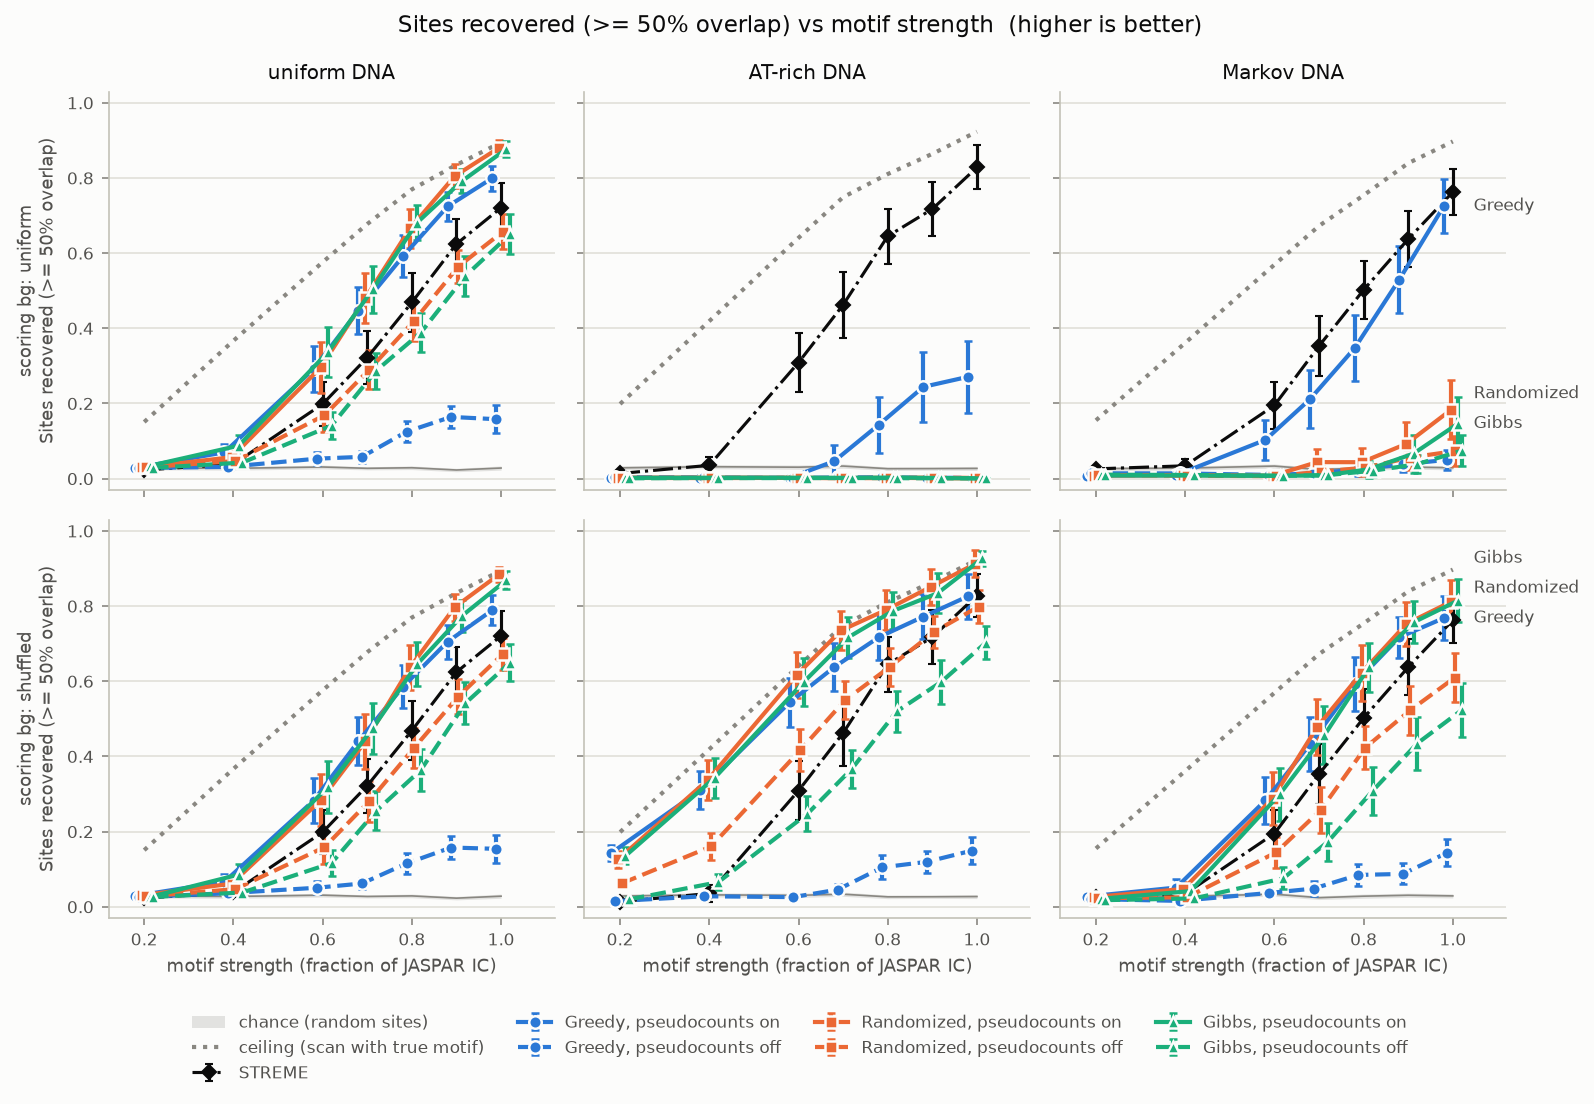

In [4]:
paths = make_all(["results/results.csv"], "results/figures")
display(Image("results/figures/overlap_rate_vs_strength.png"))

**Reading it.** On **uniform DNA** the scoring background makes no difference (top and bottom rows match), as it should. On **AT-rich** and **Markov** DNA, scoring against a uniform background makes Randomized and Gibbs chase A/T-rich junk and recover almost nothing; a shuffled background fixes this. Without pseudocounts (dashed), Greedy collapses everywhere.

#### pearson_true

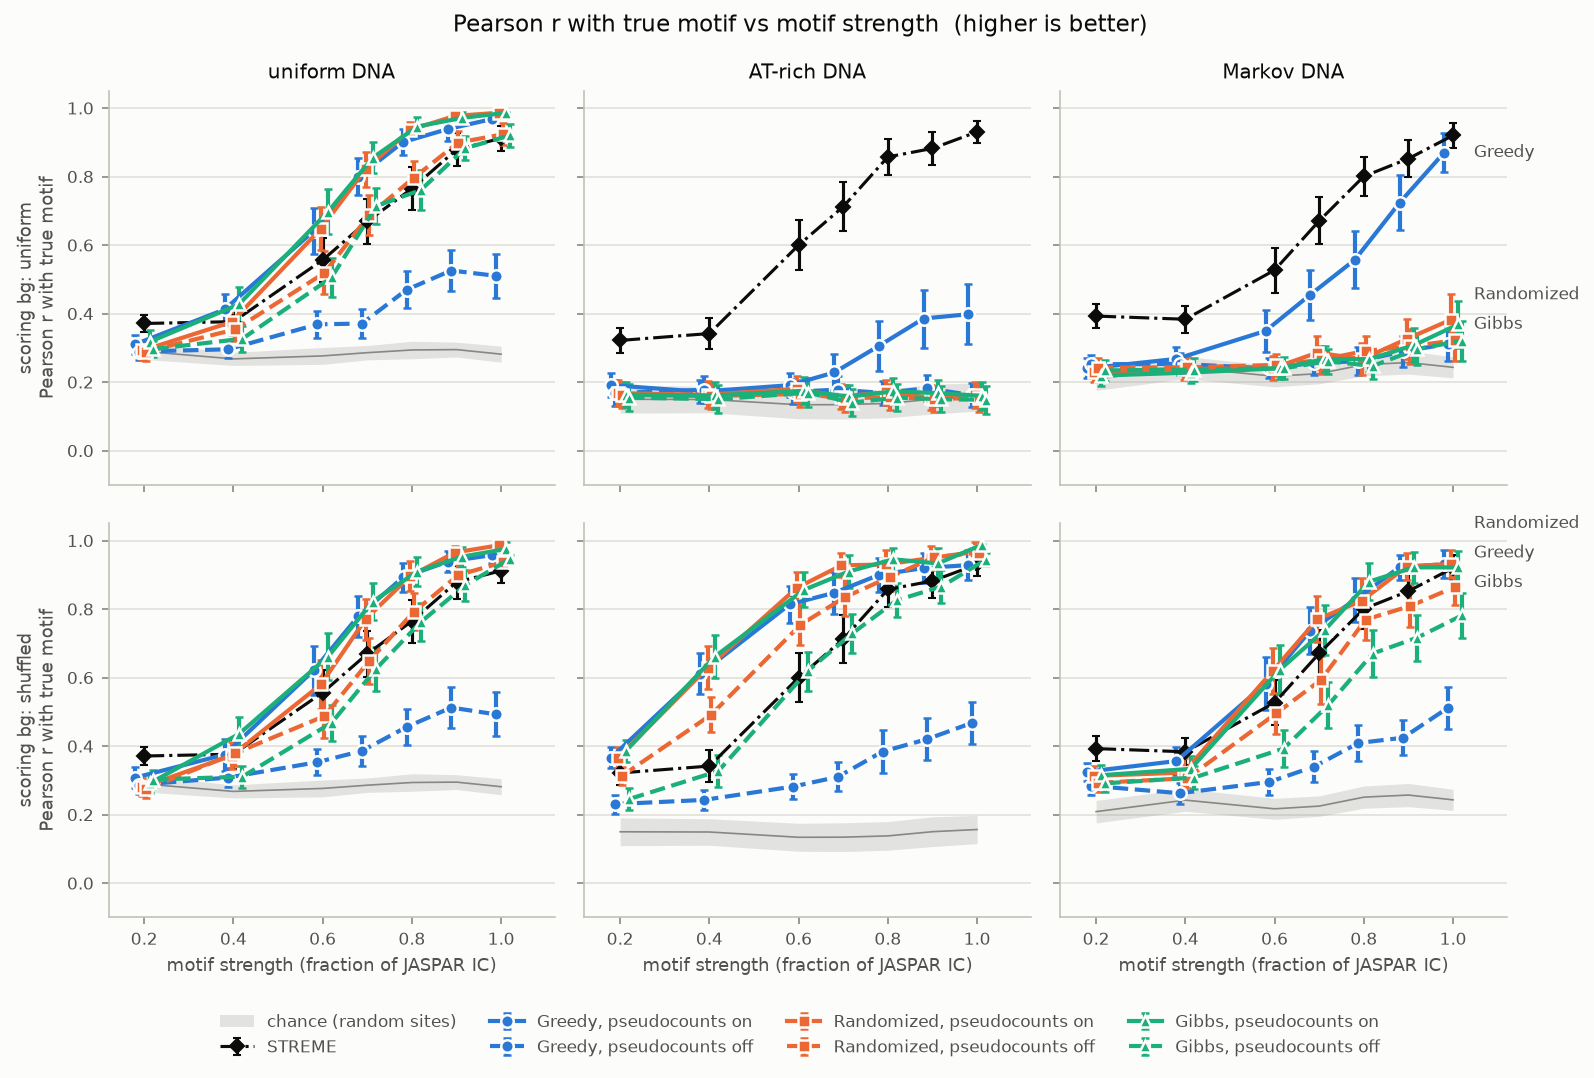

#### hamming_norm

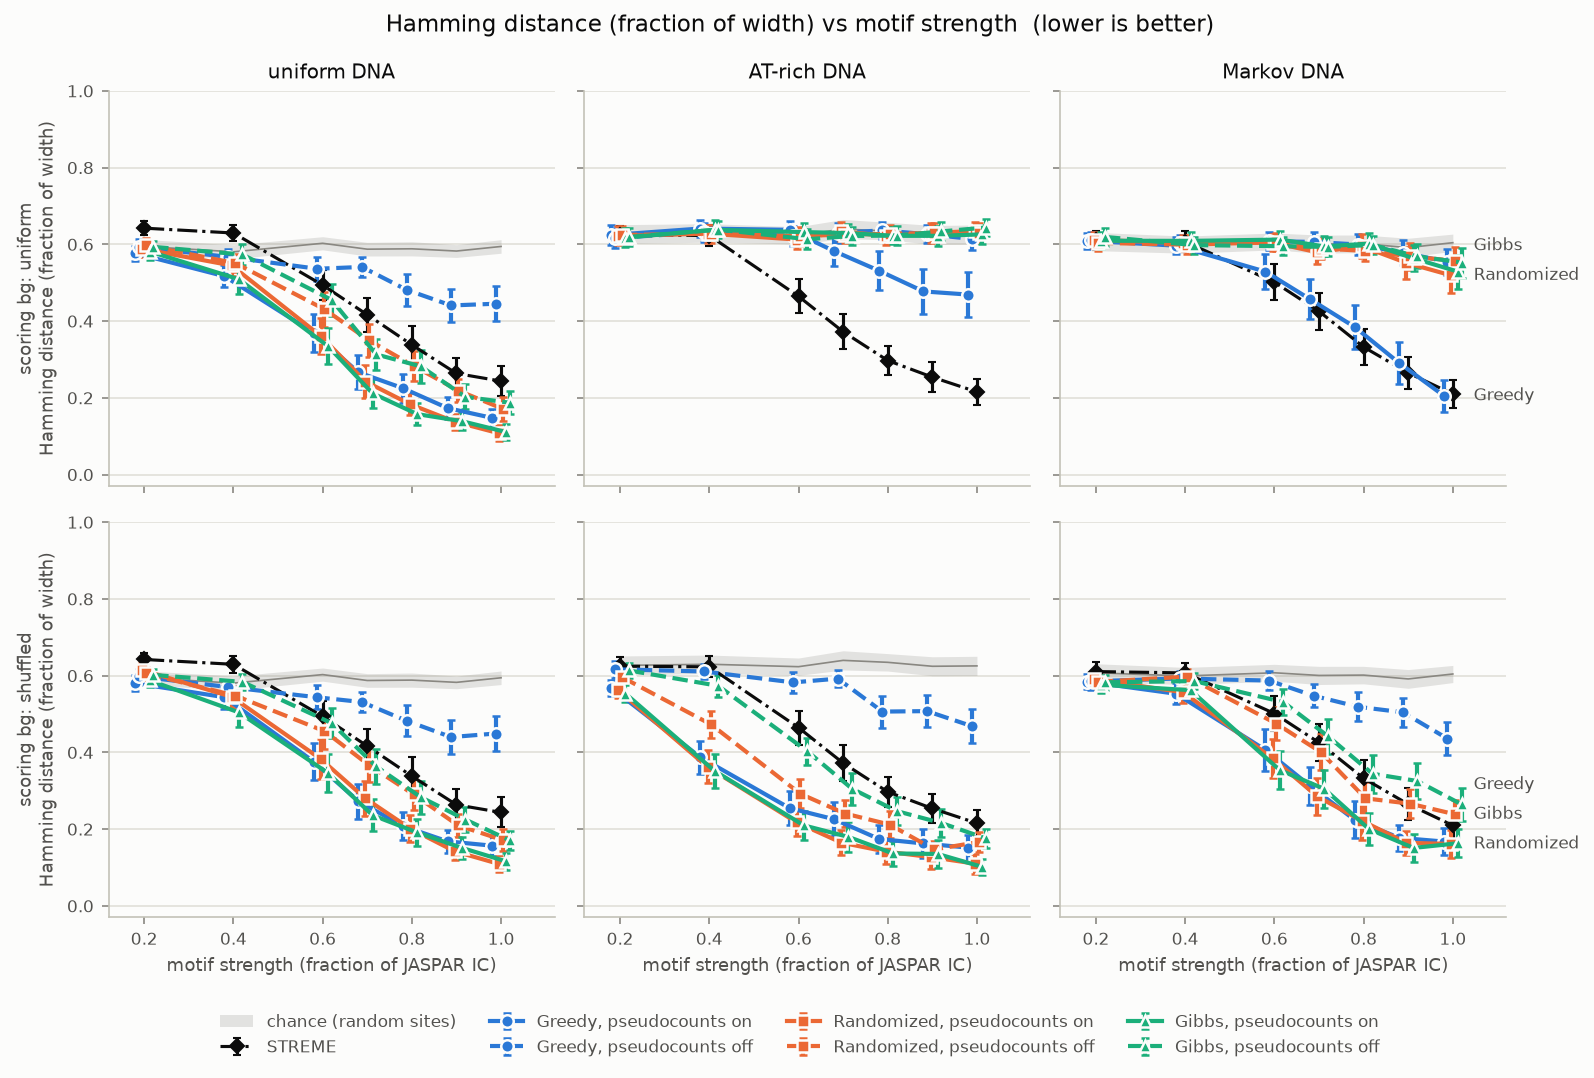

#### exact_rate

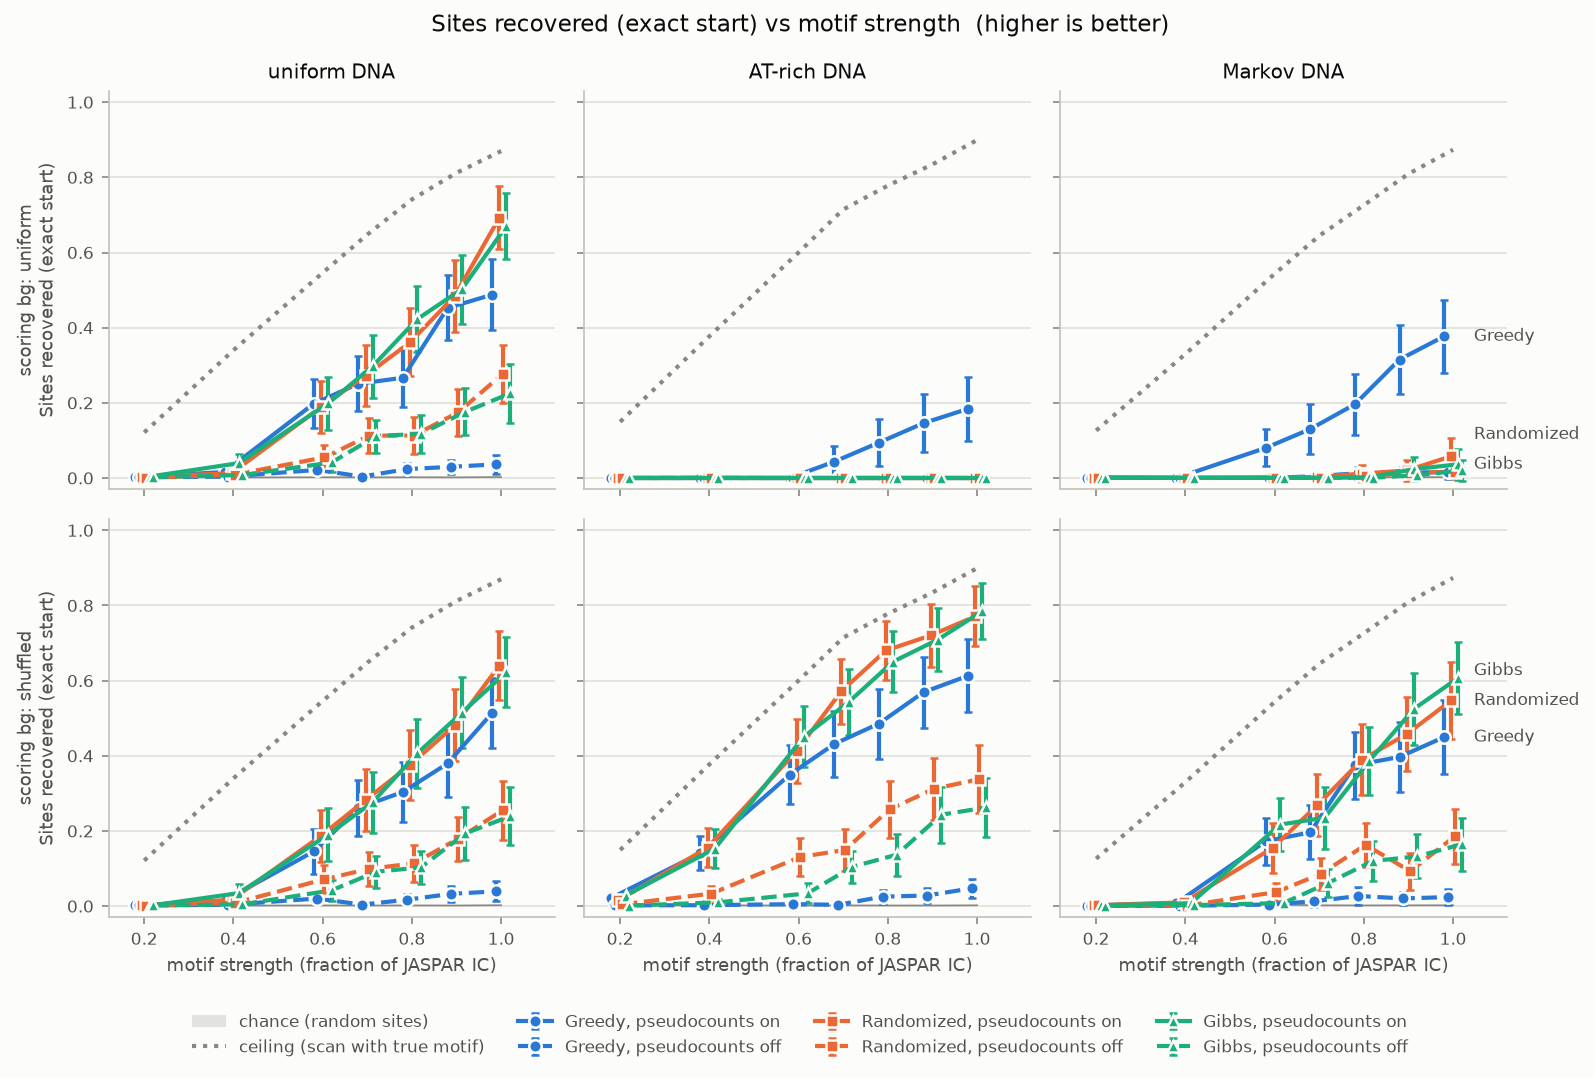

#### found_entropy

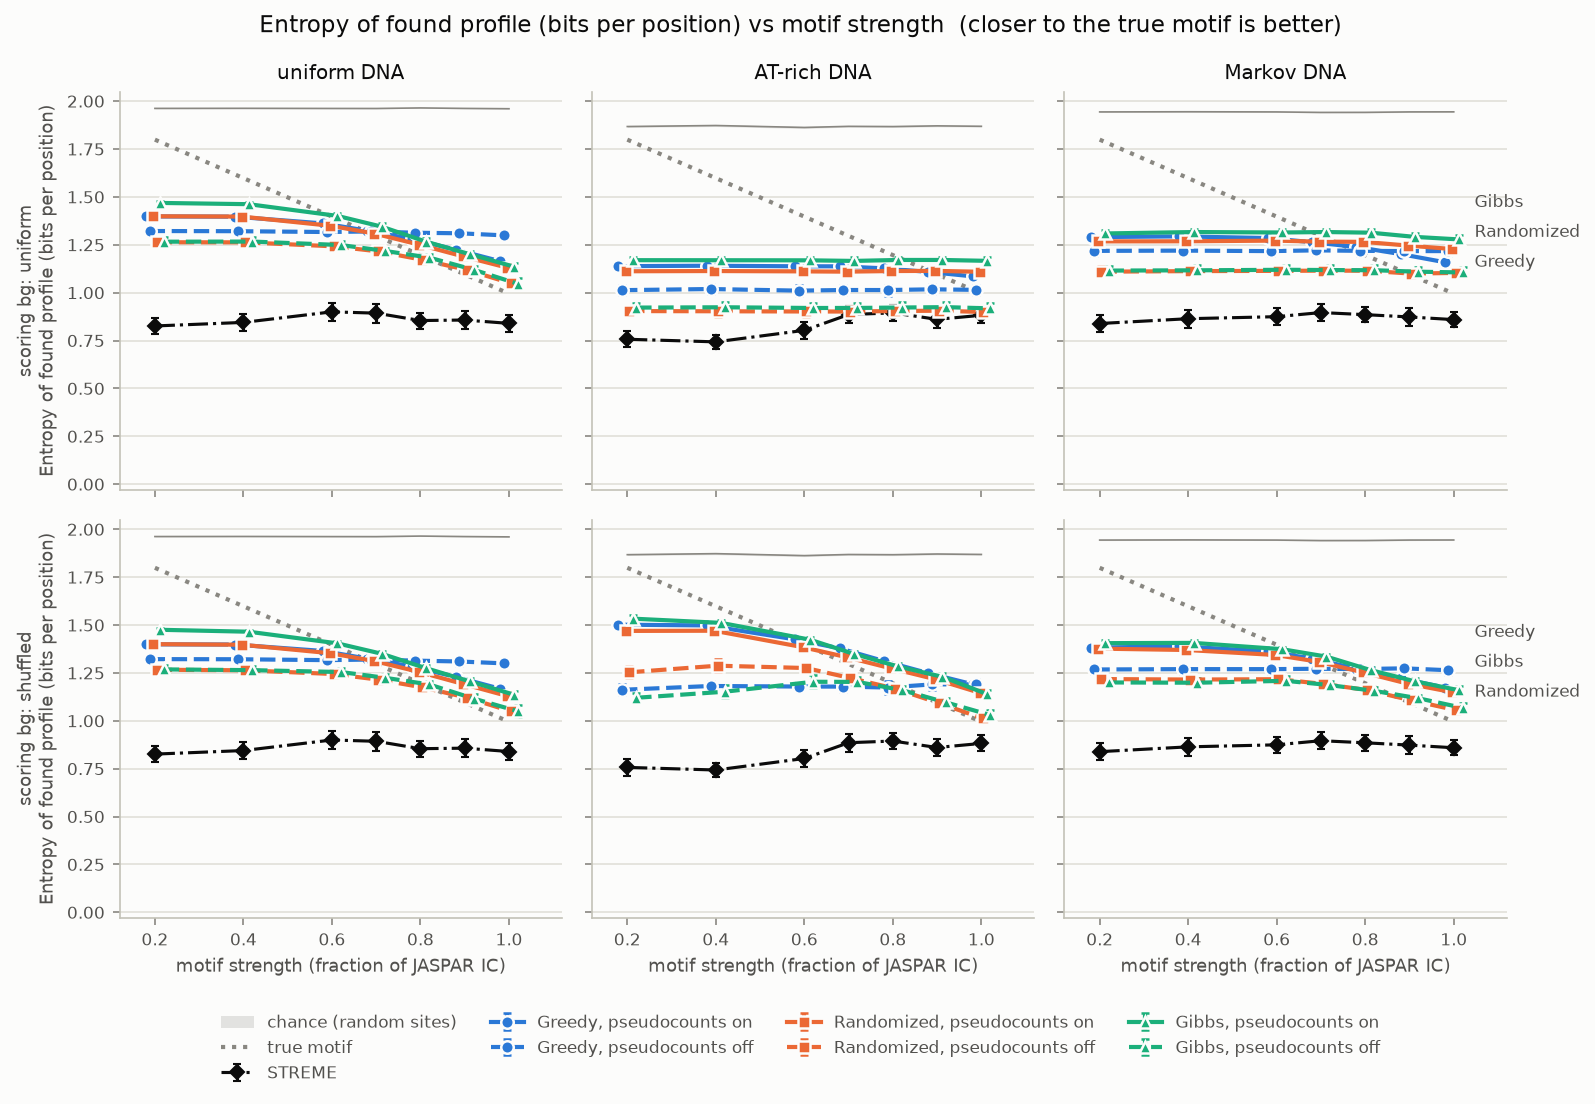

In [5]:
for m in ["pearson_true", "hamming_norm", "exact_rate", "found_entropy"]:
    display(Markdown(f"#### {m}"))
    display(Image(f"results/figures/{m}_vs_strength.png"))

## 3 · Statistical tests

Paired Wilcoxon signed-rank tests: each comparison is made **on the same datasets**, which removes the large variation between strong and weak motifs. Effect size `effect_r` is the matched-pairs rank-biserial correlation (|r| ≈ 0.1 small, 0.3 medium, ≥ 0.5 large). P-values are Holm-corrected across all claims in a table.

In [6]:
def show_claims(d, metric="overlap_rate"):
    t = standard_claims(d, metric)
    cols = ["claim", "n", "mean_a", "mean_b", "mean_diff", "wins", "losses", "ties",
            "effect_r", "p_holm", "significant"]
    return t[cols].round(4)

show_claims(syn)

,claim,n,mean_a,mean_b,mean_diff,wins,losses,ties,effect_r,p_holm,significant
0,greedy: pseudocounts on > off,3360,0.0555,0.3648,0.3093,2147,412,801,0.8935,0.0000,True
1,randomized: pseudocounts on > off,3360,0.2362,0.3369,0.1007,1838,425,1097,0.8239,0.0000,True
2,gibbs: pseudocounts on > off,3360,0.1982,0.3372,0.1390,1913,427,1020,0.8295,0.0000,True
3,greedy: shuffled bg > uniform bg [at_rich DNA],1120,0.0523,0.3171,0.2648,796,55,269,0.9655,0.0000,True
4,greedy: shuffled bg > uniform bg [markov DNA],1120,0.1500,0.2365,0.0865,601,195,324,0.6367,0.0000,True
5,greedy: shuffled bg > uniform bg [uniform DNA],1120,0.2551,0.2500,-0.0050,204,230,686,-0.1048,0.1165,False
6,randomized: shuffled bg > uniform bg [at_rich...,1120,0.0019,0.5519,0.5500,1053,17,50,0.9971,0.0000,True
7,randomized: shuffled bg > uniform bg [markov ...,1120,0.0422,0.3596,0.3174,831,107,182,0.9185,0.0000,True
8,randomized: shuffled bg > uniform bg [uniform...,1120,0.3850,0.3788,-0.0063,376,397,347,-0.0414,0.3188,False
9,gibbs: shuffled bg > uniform bg [at_rich DNA],1120,0.0017,0.4904,0.4887,1006,13,101,0.9974,0.0000,True


The same claims on **Pearson correlation with the true matrix**, which judges the *shape* of the found motif rather than where its sites are:

In [7]:
show_claims(syn, "pearson_true")

,claim,n,mean_a,mean_b,mean_diff,wins,losses,ties,effect_r,p_holm,significant
0,greedy: pseudocounts on > off,3360,0.3229,0.6011,0.2782,2550,810,0,0.7273,0.0000,True
1,randomized: pseudocounts on > off,3360,0.5057,0.5560,0.0503,2339,1011,10,0.3916,0.0000,True
2,gibbs: pseudocounts on > off,3360,0.4722,0.5647,0.0925,2427,930,3,0.4868,0.0000,True
3,greedy: shuffled bg > uniform bg [at_rich DNA],1120,0.2200,0.5518,0.3318,891,219,10,0.7942,0.0000,True
4,greedy: shuffled bg > uniform bg [markov DNA],1120,0.3805,0.5149,0.1344,725,367,28,0.4663,0.0000,True
5,greedy: shuffled bg > uniform bg [uniform DNA],1120,0.5572,0.5477,-0.0094,315,344,461,-0.0796,0.0768,False
6,randomized: shuffled bg > uniform bg [at_rich...,1120,0.1613,0.7739,0.6127,1012,108,0,0.9520,0.0000,True
7,randomized: shuffled bg > uniform bg [markov ...,1120,0.2777,0.6313,0.3536,896,220,4,0.7812,0.0000,True
8,randomized: shuffled bg > uniform bg [uniform...,1120,0.6789,0.6619,-0.0170,477,526,117,-0.0819,0.0491,True
9,gibbs: shuffled bg > uniform bg [at_rich DNA],1120,0.1589,0.7311,0.5722,1010,110,0,0.9406,0.0000,True


## 4 · Question 3: how much of the gap to STREME do the two fixes explain?

`plain` = textbook settings (no pseudocounts, uniform background); `best` = both fixes.

In [8]:
gap = pd.concat([streme_gap(syn).assign(data="synthetic"),
                 streme_gap(real).assign(data="real_sites")])
gap.round(3)

,algorithm,metric,streme,plain,best,gap_plain,gap_best,fraction_closed,data
0,greedy,overlap_rate,0.377,0.038,0.463,0.339,-0.086,1.253,synthetic
1,randomized,overlap_rate,0.377,0.114,0.502,0.263,-0.124,1.473,synthetic
2,gibbs,overlap_rate,0.377,0.108,0.503,0.270,-0.126,1.467,synthetic
0,greedy,overlap_rate,0.802,0.035,0.786,0.767,0.016,0.979,real_sites
1,randomized,overlap_rate,0.802,0.192,0.876,0.610,-0.074,1.121,real_sites
2,gibbs,overlap_rate,0.802,0.178,0.881,0.624,-0.079,1.126,real_sites


Where `fraction_closed` > 1 the algorithm closes the whole gap **and overtakes** STREME.

> ⚠️ **Caveat.** Greedy / Randomized / Gibbs were told the true motif width; STREME had to find it (`algorithms_know_true_width` above). The comparison is fair on everything else (same datasets, same evaluation), but "beats STREME" holds only under this condition.

## 5 · Question 1: when is each algorithm reliable?

Lowest strength (fraction of JASPAR IC) at which mean site recovery reaches **50 %**, per DNA background. `never` = not reached even at full strength. `- / -` = methods without the two switches (STREME, the ceiling).

In [9]:
def reliable_table(d, level):
    r = reliability(d, level=level)
    r["config"] = r.pseudocount.fillna("-") + " / " + r.bg_model
    keep = ["greedy", "randomized", "gibbs", "streme", "oracle_scan"]
    r = r[r.algorithm.isin(keep)]
    t = (r.set_index(["algorithm", "config", "data_bg"])["reliable_from_strength"]
          .unstack("data_bg").reindex(columns=["uniform", "at_rich", "markov"]))
    return t.fillna("never")

reliable_table(syn, 0.5)

C:\Users\Adeel Asghar\AppData\Local\Temp\ipykernel_28880\1105448104.py:8: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  return t.fillna("never")


data_bg                    uniform at_rich markov
algorithm   config                               
gibbs       off / shuffled     0.9     0.8    1.0
            off / uniform      0.9   never  never
            on / shuffled      0.8     0.6    0.8
            on / uniform       0.7   never  never
greedy      off / shuffled   never   never  never
            off / uniform    never   never  never
            on / shuffled      0.8     0.6    0.8
            on / uniform       0.8   never    0.9
oracle_scan - / -              0.6     0.6    0.6
randomized  off / shuffled     0.9     0.7    0.9
            off / uniform      0.9   never  never
            on / shuffled      0.8     0.6    0.8
            on / uniform       0.8   never  never
streme      - / -              0.9     0.8    0.8

In [10]:
reliable_table(syn, 0.8)

C:\Users\Adeel Asghar\AppData\Local\Temp\ipykernel_28880\1105448104.py:8: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  return t.fillna("never")


data_bg                    uniform at_rich markov
algorithm   config                               
gibbs       off / shuffled   never   never  never
            off / uniform    never   never  never
            on / shuffled      1.0     0.9    1.0
            on / uniform       1.0   never  never
greedy      off / shuffled   never   never  never
            off / uniform    never   never  never
            on / shuffled    never     1.0  never
            on / uniform     never   never  never
oracle_scan - / -              0.9     0.8    0.9
randomized  off / shuffled   never   never  never
            off / uniform    never   never  never
            on / shuffled      1.0     0.9    1.0
            on / uniform       0.9   never  never
streme      - / -            never     1.0  never

### Not every motif is equally hard

Site recovery of the best classic configuration (Gibbs, pseudocounts on, shuffled background) and STREME, per motif, averaged over all strengths and backgrounds. Motifs with high information content (MA0007.3, MA0009.2: ~19 bits at full strength) are much easier.

In [11]:
best = syn[(syn.algorithm == "gibbs") & (syn.pseudocount == "on") & (syn.bg_model == "shuffled")]
per_motif = pd.DataFrame({
    "full_strength_IC": syn.groupby("motif_id").true_ic.max().round(1),
    "gibbs_best": best.groupby("motif_id").overlap_rate.mean(),
    "streme": syn[syn.algorithm == "streme"].groupby("motif_id").overlap_rate.mean(),
    "ceiling": syn[syn.algorithm == "oracle_scan"].groupby("motif_id").overlap_rate.mean(),
}).round(3).sort_values("full_strength_IC")
per_motif

,full_strength_IC,gibbs_best,streme,ceiling
motif_id,,,,
MA0002.2,10.4,0.313,0.191,0.467
MA0014.3,11.1,0.503,0.357,0.594
MA0001.3,11.4,0.253,0.140,0.524
MA0018.4,11.5,0.415,0.312,0.541
MA0003.4,11.7,0.531,0.433,0.646
MA0017.2,13.3,0.565,0.339,0.629
MA0007.3,18.7,0.725,0.619,0.806
MA0009.2,19.0,0.720,0.625,0.795


## 6 · Real JASPAR binding sites

90 datasets: real binding sites of MA0003.4, MA0014.3 and MA0018.4 from JASPAR 2026, embedded in synthetic flanking DNA (uniform, AT-rich, Markov) so the task is not trivially easy. There are no strength levels here, so each method is one dot.

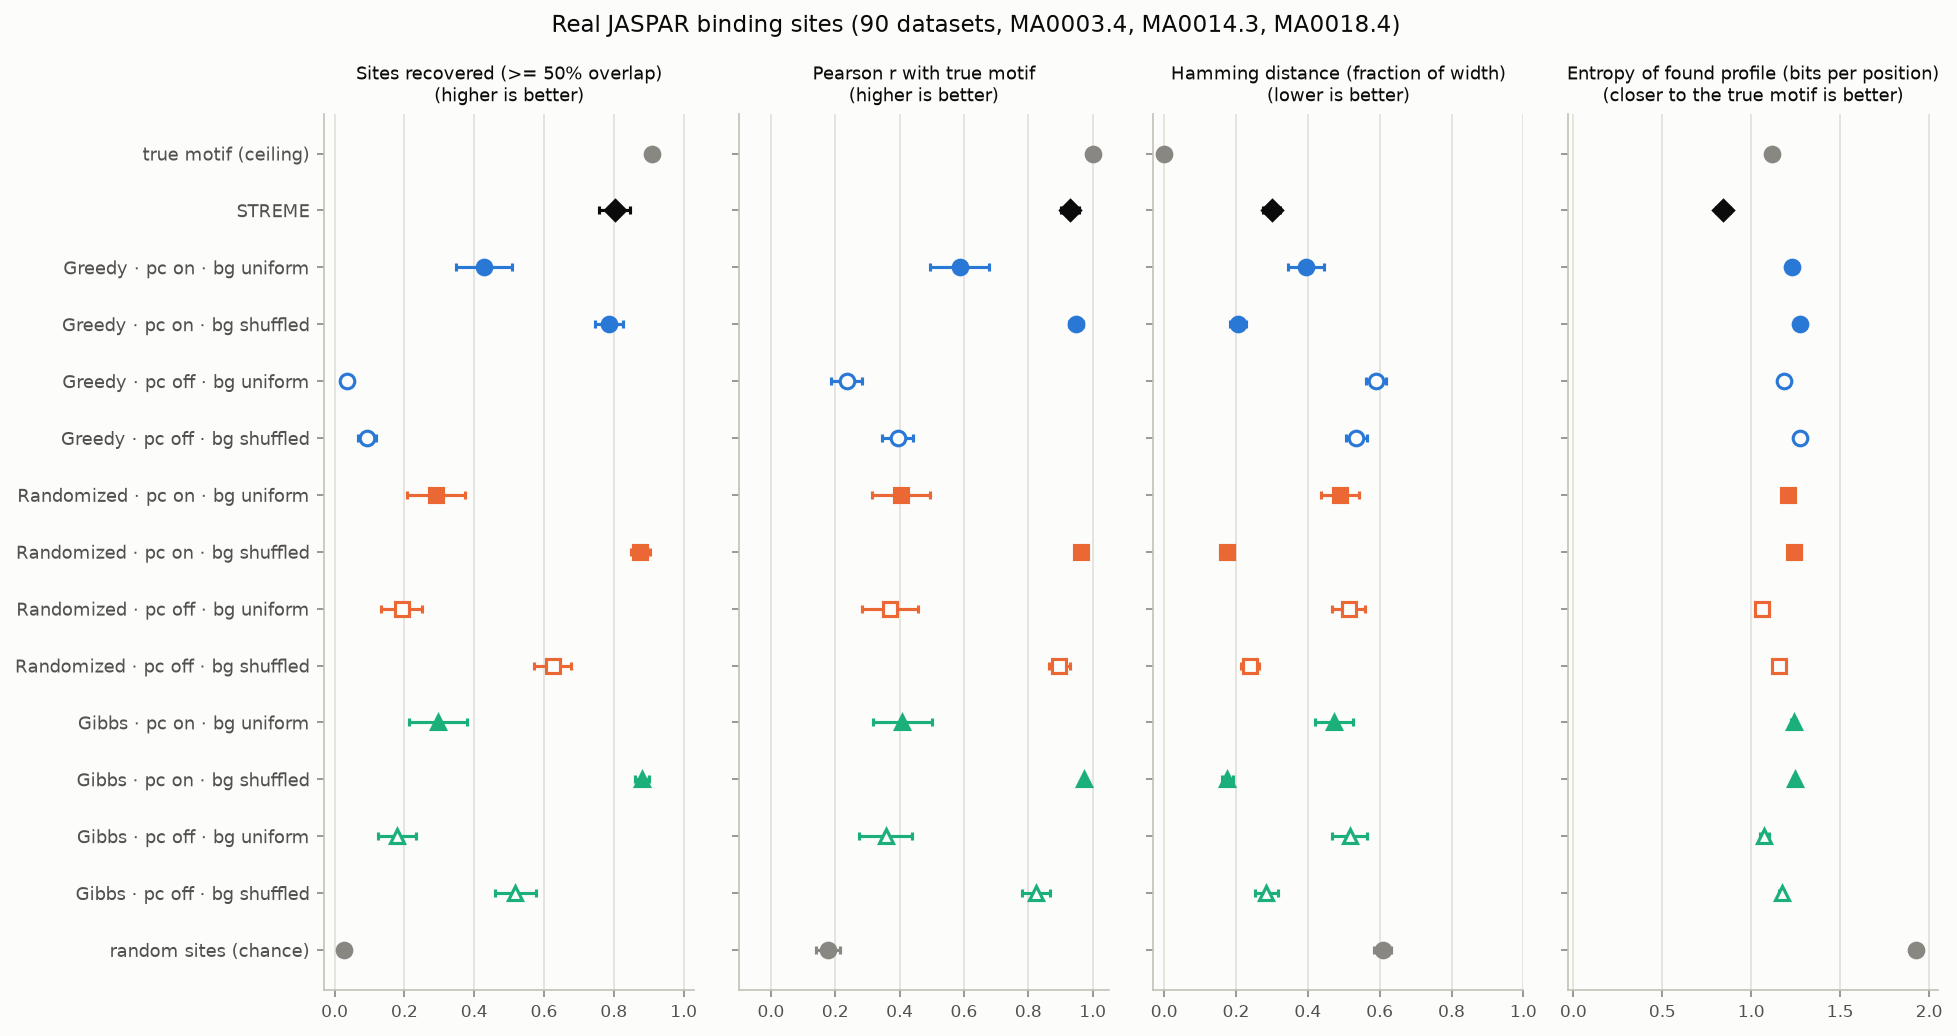

,claim,n,mean_a,mean_b,mean_diff,wins,losses,ties,effect_r,p_holm,significant
0,greedy: pseudocounts on > off,180,0.0639,0.6070,0.5431,142,6,32,0.9931,0.0000,True
1,randomized: pseudocounts on > off,180,0.4084,0.5828,0.1743,121,3,56,0.9917,0.0000,True
2,gibbs: pseudocounts on > off,180,0.3479,0.5888,0.2409,125,6,49,0.9894,0.0000,True
3,greedy: shuffled bg > uniform bg [at_rich DNA],60,0.0010,0.5033,0.5023,52,0,8,1.0000,0.0000,True
4,greedy: shuffled bg > uniform bg [markov DNA],60,0.2823,0.4237,0.1413,33,8,19,0.7062,0.0004,True
5,greedy: shuffled bg > uniform bg [uniform DNA],60,0.4113,0.3910,-0.0203,12,19,29,-0.2762,0.1792,False
6,randomized: shuffled bg > uniform bg [at_rich...,60,0.0000,0.8733,0.8733,60,0,0,1.0000,0.0000,True
7,randomized: shuffled bg > uniform bg [markov ...,60,0.0107,0.6987,0.6880,57,1,2,0.9982,0.0000,True
8,randomized: shuffled bg > uniform bg [uniform...,60,0.7113,0.6797,-0.0317,14,26,20,-0.3805,0.1186,False
9,gibbs: shuffled bg > uniform bg [at_rich DNA],60,0.0000,0.8093,0.8093,60,0,0,1.0000,0.0000,True


In [12]:
display(Image("results/figures/real_data.png"))
show_claims(real)

## 7 · Is it the search or the scoring?

A failure can mean the search **gave up too early**, or that the **scoring model rewards the wrong thing**. The budget study (`results/budget_study.csv`) reruns Randomized and Gibbs with growing budgets. `search_ok` is the share of runs whose found motif scores **at least as high as the planted sites** under the algorithm's own score: when it is high but recovery is low, more search cannot help, and the model is at fault.

In [13]:
b = pd.read_csv("results/budget_study.csv")
b.groupby(["algorithm", "budget"])[["overlap_rate", "search_ok"]].mean().round(3)

overlap_rate  search_ok
algorithm  budget                         
gibbs      1250           0.017      0.000
           5000           0.032      0.125
           20000          0.148      0.208
           80000          0.368      0.583
randomized 25             0.120      0.417
           50             0.160      0.458
           100            0.312      0.667
           200            0.433      0.875
           400            0.493      0.917

In [14]:
rt = df[df.algorithm.isin(["greedy", "randomized", "gibbs", "streme"])]
rt.groupby("algorithm").runtime_s.agg(["mean", "median", "max"]).round(2).sort_values("mean")

,mean,median,max
algorithm,,,
greedy,2.01,2.18,4.23
streme,3.81,3.69,9.73
randomized,4.30,4.25,8.18
gibbs,14.61,16.50,27.26


## 8 · Conclusions

1. **The background model is the single largest factor.** On AT-rich and Markov DNA, scoring against a uniform background makes Randomized and Gibbs recover almost no sites (≤ 4 %); a shuffled-sequence background raises their site recovery by **+0.49 to +0.55** on AT-rich and **+0.30 to +0.32** on Markov DNA, with near-perfect effect sizes (r ≥ 0.9). Greedy gains less (+0.26 / +0.09). On uniform DNA the choice makes no practical difference (|Δ| ≤ 0.02), as expected.
2. **Laplace pseudocounts help every algorithm and are essential for Greedy**, whose recovery collapses without them (+0.31 on synthetic data, +0.54 on real sites). Without pseudocounts one unseen base sends a whole window's score to −∞.
3. **Together the two fixes close the entire gap to STREME, and pass it.** Textbook settings recover 4–11 % of sites; with both fixes, about 50 % against STREME's 38 % on synthetic data, and 0.79–0.88 against 0.80 on real binding sites. This holds **with the true motif width given** to the classic algorithms.
4. **Reliability depends on motif strength and on the motif itself.** Even scanning with the *true* matrix only reaches 50 % site recovery at 60 % of the JASPAR information content, so poor results below that are a limit of the data, not of the algorithms. With both fixes, Randomized and Gibbs reach 50 % at 60–80 % strength and 80 % at 90–100 %; STREME reaches 50 % at 80–90 %. High-information motifs (MA0007.3, MA0009.2) are far easier than low ones.
5. **Gibbs is held back partly by its search budget, Randomized mostly by its model.** In the budget study, Randomized's found motif already scores at least as well as the planted sites in 88 % of runs at the budget used, so more search would help little; for Gibbs this is only 58 % and recovery is still rising, so the Gibbs results are a **lower bound**.
6. **Weak motifs produce over-confident answers.** At low strength the found profiles have *lower* entropy than the true motif: the search locks onto chance patterns that only look conserved.

**Limitations.** 8 motifs; real binding sites embedded in synthetic flanks rather than genomic DNA; STREME run with default settings; classic algorithms given the true width; Gibbs search budget not saturated; site-recovery ceiling computed with a uniform background.